### Import libraries and load the CSV

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the results calculated in your previous notebook
file_path = "Large_cap/analysis/large_cap_fund_results.csv"

large_cap_results = pd.read_csv(file_path)

# Convert date columns to datetime
large_cap_results["Start Date"] = pd.to_datetime(
    large_cap_results["Start Date"]
)
large_cap_results["End Date"] = pd.to_datetime(
    large_cap_results["End Date"]
)

# Create folder for charts
os.makedirs("Large_cap/analysis/charts", exist_ok=True)

display(large_cap_results.head())


,Fund,Start Date,End Date,Observations,Start NAV,End NAV,CAGR,Volatility,Maximum Drawdown,Sharpe Ratio
0,Nippon India Large Cap,2022-01-03,2025-12-31,985,54.3991,105.3421,0.180049,0.136721,-0.153680,0.880623
1,ICICI Prudential Large Cap,2022-01-03,2025-12-31,985,71.0800,127.1700,0.156883,0.123998,-0.153933,0.793930
2,HDFC Large Cap,2022-01-03,2025-12-31,985,732.7530,1279.9530,0.149963,0.131588,-0.163646,0.708972
3,DSP Large Cap,2022-01-03,2025-12-31,985,312.6130,534.9380,0.144048,0.124441,-0.176848,0.699834
4,Bandhan Large Cap,2022-01-03,2025-12-31,991,56.4500,92.7700,0.132523,0.135343,-0.194181,0.571672


### Charts

### CAGR comparison

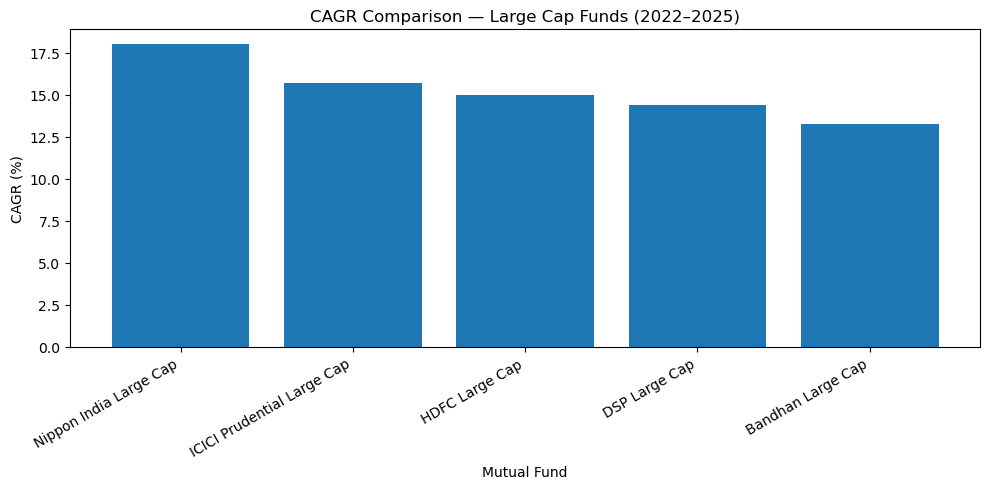

In [2]:
plot_data = large_cap_results.sort_values(
    "CAGR", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["CAGR"] * 100)
plt.title("CAGR Comparison — Large Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("CAGR (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_cagr.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Annualized volatility

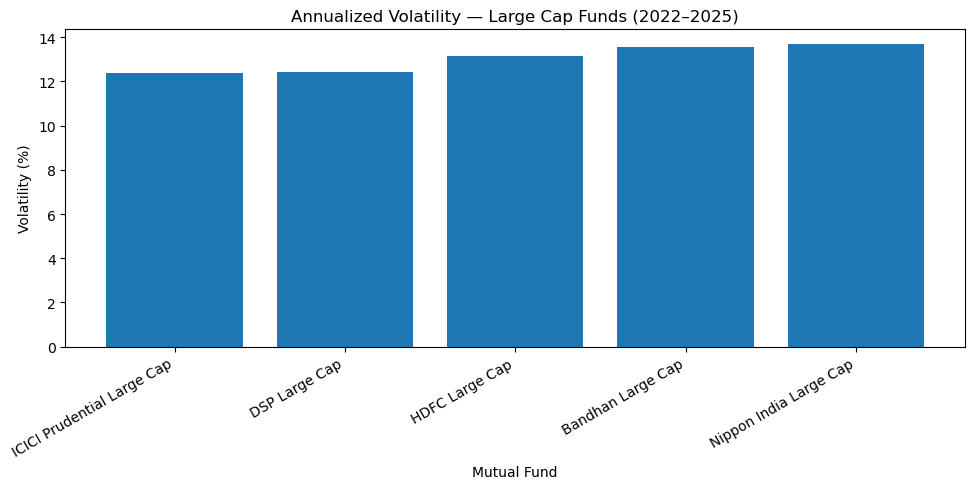

In [3]:
plot_data = large_cap_results.sort_values(
    "Volatility", ascending=True
)

plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["Volatility"] * 100)
plt.title("Annualized Volatility — Large Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Volatility (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_volatility.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Maximum drawdown

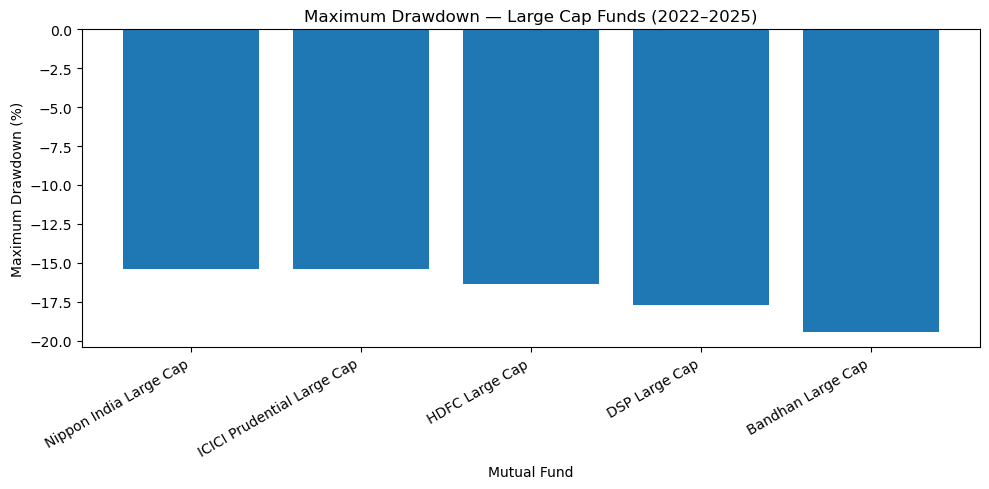

In [4]:
plot_data = large_cap_results.sort_values(
    "Maximum Drawdown", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    plot_data["Fund"],
    plot_data["Maximum Drawdown"] * 100
)
plt.title("Maximum Drawdown — Large Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Maximum Drawdown (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_max_drawdown.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Sharpe ratio

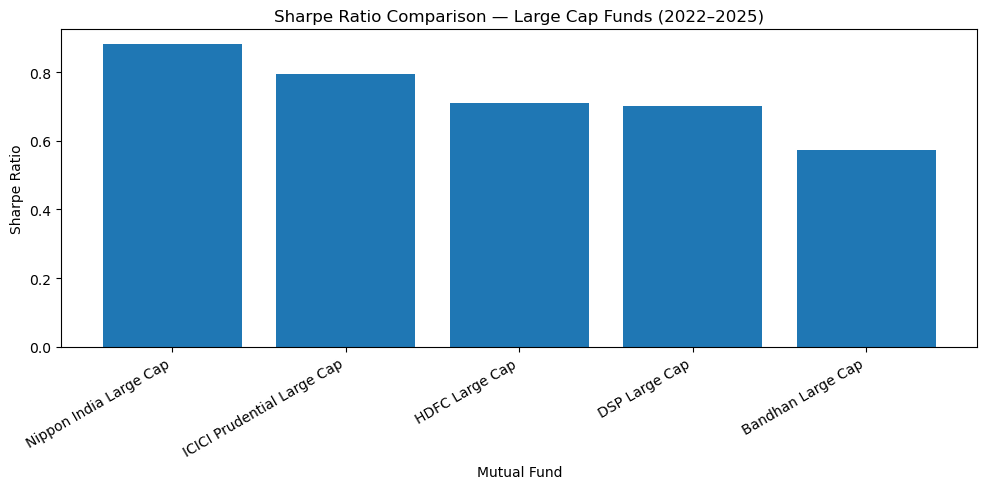

In [5]:
plot_data = large_cap_results.sort_values(
    "Sharpe Ratio", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(plot_data["Fund"], plot_data["Sharpe Ratio"])
plt.title("Sharpe Ratio Comparison — Large Cap Funds (2022–2025)")
plt.xlabel("Mutual Fund")
plt.ylabel("Sharpe Ratio")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_sharpe.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Risk vs. return scatter plot

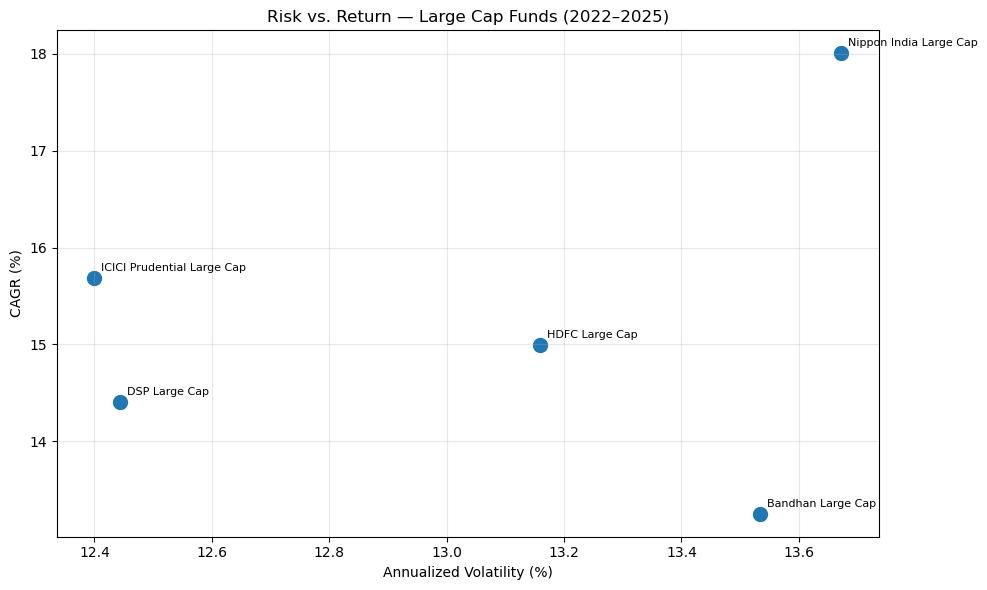

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    large_cap_results["Volatility"] * 100,
    large_cap_results["CAGR"] * 100,
    s=100
)

for _, row in large_cap_results.iterrows():
    plt.annotate(
        row["Fund"],
        (
            row["Volatility"] * 100,
            row["CAGR"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Risk vs. Return — Large Cap Funds (2022–2025)")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("CAGR (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_risk_return.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Performance metrics heatmap

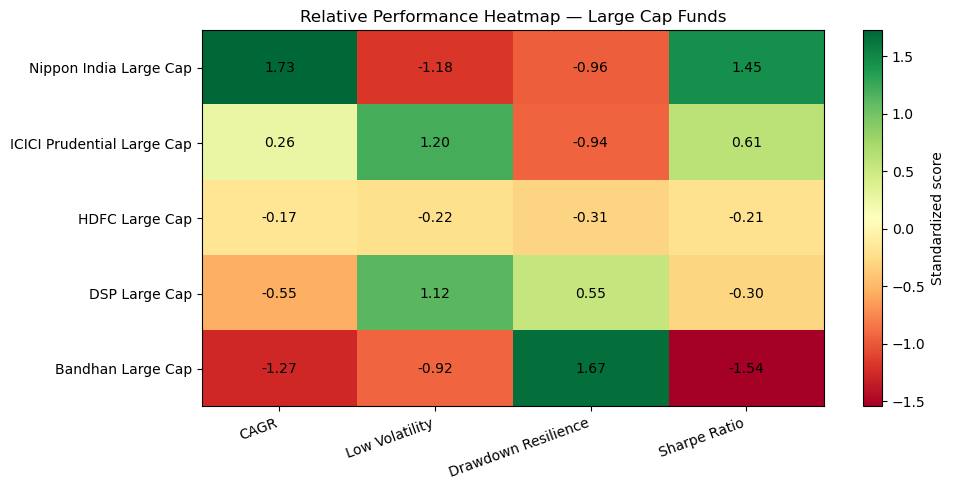

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metrics = large_cap_results.set_index("Fund")[
    ["CAGR", "Volatility", "Maximum Drawdown", "Sharpe Ratio"]
].copy()

# Higher values should represent better outcomes for every metric
metrics["Maximum Drawdown"] = -metrics["Maximum Drawdown"]
metrics["Volatility"] = -metrics["Volatility"]

# Standardize each metric across the five funds
scores = (metrics - metrics.mean()) / metrics.std(ddof=0)

plt.figure(figsize=(10, 5))

image = plt.imshow(scores, aspect="auto", cmap="RdYlGn")

plt.xticks(
    range(len(scores.columns)),
    ["CAGR", "Low Volatility", "Drawdown Resilience", "Sharpe Ratio"],
    rotation=20,
    ha="right"
)

plt.yticks(range(len(scores.index)), scores.index)

for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(
            j, i, f"{scores.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.colorbar(image, label="Standardized score")
plt.title("Relative Performance Heatmap — Large Cap Funds")
plt.tight_layout()

plt.savefig(
    "Large_cap/analysis/charts/large_cap_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Radar chart

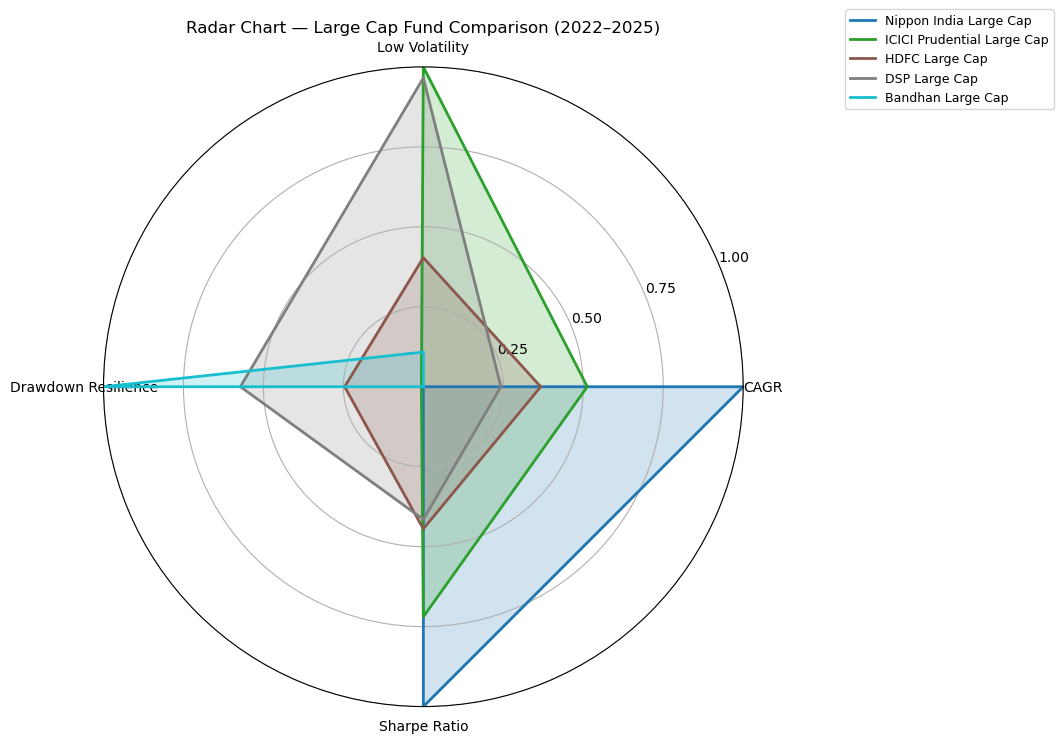

Radar chart saved successfully.


In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Select the metrics to compare
metrics = large_cap_results.set_index("Fund")[
    ["CAGR", "Volatility", "Maximum Drawdown", "Sharpe Ratio"]
].copy()

# Convert risk metrics so higher values indicate better outcomes
metrics["Volatility"] = -metrics["Volatility"]
metrics["Maximum Drawdown"] = -metrics["Maximum Drawdown"]

# Normalize metrics between 0 and 1
min_values = metrics.min()
max_values = metrics.max()

normalized = (metrics - min_values) / (max_values - min_values)
normalized = normalized.fillna(0)

# Radar chart categories
categories = [
    "CAGR",
    "Low Volatility",
    "Drawdown Resilience",
    "Sharpe Ratio"
]

num_vars = len(categories)

angles = np.linspace(
    0, 2 * np.pi, num_vars, endpoint=False
).tolist()

angles += angles[:1]

# Create radar chart
fig, ax = plt.subplots(
    figsize=(10, 9),
    subplot_kw={"polar": True}
)

# Different colors for each fund
colors = plt.cm.tab10(
    np.linspace(0, 1, len(normalized))
)

for (fund_name, row), color in zip(
    normalized.iterrows(), colors
):
    values = row.tolist()
    values += values[:1]

    # Draw the outline
    ax.plot(
        angles,
        values,
        linewidth=2,
        color=color,
        label=fund_name
    )

    # Fill the radar area
    ax.fill(
        angles,
        values,
        color=color,
        alpha=0.20
    )

# Configure axes and labels
ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=10)
ax.set_ylim(0, 1)

ax.set_yticks([0.25, 0.50, 0.75, 1.00])
ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"])

ax.set_title(
    "Radar Chart — Large Cap Fund Comparison (2022–2025)",
    pad=25
)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.15, 1.10),
    fontsize=9
)

plt.tight_layout()

# Save chart
os.makedirs("Large_cap/analysis/charts", exist_ok=True)

plt.savefig(
    "Large_cap/analysis/charts/large_cap_radar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Radar chart saved successfully.")
